# Practical Exercise 4: The Autonomous Trailer as a Knowledge-Based Agent
**ICS 3202 Artificial Intelligence** | Nairobi to Kisumu

## Group members
| Student number | Name |
|---|---|
| 189984 | Muriuki Alvin Murithi |
| 192576 | Sebudde Jeremy Mwesigwa |
| 189588 | Mutungi Travis Njenga |

**Repository:** [cypher-30/Knowledge-Engineering](https://github.com/cypher-30/Knowledge-Engineering)

## What this notebook does
A **knowledge-based agent** is a program that keeps a store of facts and rules (its **knowledge base**, or KB) and decides what to do by looking things up in that store and reasoning with it, instead of having every decision hard-coded.

We follow the lecturer's knowledge engineering steps (Steps 1 to 10) to turn our self-driving trailer from Practical Exercise 3 into such an agent. Its knowledge base holds:

* the **road network** from Exercise 3 (towns, roads, Google Maps distances) and the **Uniform Cost Search** that finds the shortest route,
* **driving rules** for traffic signals, road signs and weather,
* **live weather** for each town, pulled from the free Open-Meteo API.

The user talks to the agent with simple text prompts (type a signal, a sign, or a new fact). When the notebook runs without a keyboard (for example when it is run automatically), each prompt uses a sensible default answer so the notebook still runs to the end.

## Step 1: Identify the Task
The trailer must **drive from Nairobi to Kisumu safely, using the shortest road route**.

On the way it has to:
* choose the route (which towns to drive through),
* react to what it sees: **traffic lights**, **road signs** and the **weather** at each town,
* when two rules disagree, follow the **most cautious** one.

Goal: *make safe driving decisions with minimal risk, while still reaching Kisumu by the shortest route.*

## Step 2: Assemble Relevant Knowledge
Where each piece of knowledge comes from:

| Knowledge | Source |
|---|---|
| Towns and roads, distance of each road (km) | Practical Exercise 3, Google Maps, measured 16 Oct 2026 (route Google recommends first) |
| Search tree and the shortest route (352.5 km) | Practical Exercise 3 Part 2, Uniform Cost Search |
| Current weather at each town | **Open-Meteo API** (https://open-meteo.com/), free, no API key |
| What to do for each signal, sign and weather type | **Our own group rules (assumptions)**. These are sensible driving rules we agreed on; they are not copied from an official Kenyan regulation. |

**API declaration.** We use the Open-Meteo forecast API to get the current weather code at each town. The code is in [`weather_api.py`](weather_api.py) in this same repository. It turns Open-Meteo's weather code into one of five words our KB understands: Clear, Cloudy, Fog, Rain, Storm. If the internet is down, it returns stored "Clear" values so the notebook still works.

In [1]:
# Load the weather API code (weather_api.py, in this repository).
# If the notebook is opened on its own (e.g. in Colab), download the file from GitHub first.
import os, urllib.request
if not os.path.exists("weather_api.py"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/cypher-30/Knowledge-Engineering/main/weather_api.py",
        "weather_api.py")
from weather_api import fetch_weather, TOWN_COORDS

# A safe replacement for input(): if no one can type (automatic run), use the default answer.
def ask(prompt, default):
    try:
        answer = input(prompt).strip()
    except Exception:
        answer = ""
    if not answer:
        answer = default
        print(f"{prompt}{answer}   (default used)")
    return answer

## Step 3: Define the Vocabulary
The **vocabulary** is the list of words (predicates and constants) the KB uses. A **predicate** is a statement that is true or false about something, like *Road(Nairobi, Naivasha, 91)*.

| Predicate | Meaning | How we store or compute it in Python |
|---|---|---|
| `Town(x)` | x is a town in our map | key of `graph` |
| `Road(a, b, km)` | there is a two-way road from a to b of length km | `graph[a][b] = km` |
| `Weather(town, condition)` | the current weather at the town | `weather_now[town]` |
| `Signal(colour)` | the trailer sees a traffic light of this colour | key of `signal_rules` |
| `Sign(type)` | the trailer sees this road sign | key of `sign_rules` |
| `Action(x)` | the action the KB gives for signal, sign or weather x | value in the rule dictionaries |
| `CanGo(x)` | true if the trailer may move on when it sees x | `can_go(...)` |
| `BestRoute(start, goal)` | the cheapest route between two towns | `best_route(...)`, which runs Uniform Cost Search |

**Constants:**
* Towns: Nairobi, Thika, Nyeri, Naivasha, Nakuru, Kericho, Eldoret, Kakamega, Kisumu
* Signals: Red, Yellow, Green
* Signs: Stop, Give Way, Speed Bump, Roadworks, Weighbridge, Sharp Bend, No Entry
* Weather: Clear, Cloudy, Fog, Rain, Storm

## Step 4: Encode General Knowledge about the Domain [3 marks]
General knowledge is what is always true in our world, whatever trip the trailer is on. As the template asks, we first **declare the vocabulary explicitly** in code (the constants from Step 3), then encode the knowledge. The weather facts come from the API declared in Step 2. We store it in plain Python dictionaries. Each rule says **what to do**, **the speed limit to use** (km/h) and **whether the trailer may keep moving**. The speeds are our group's assumptions.

In [2]:
# ---------- 0. Vocabulary (declared explicitly, from Step 3) ----------
TOWNS    = ["Nairobi", "Thika", "Nyeri", "Naivasha", "Nakuru", "Kericho", "Eldoret", "Kakamega", "Kisumu"]
SIGNALS  = ["Red", "Yellow", "Green"]
SIGNS    = ["Stop", "Give Way", "Speed Bump", "Roadworks", "Weighbridge", "Sharp Bend", "No Entry"]
WEATHER  = ["Clear", "Cloudy", "Fog", "Rain", "Storm"]
PREDICATES = ["Town(x)", "Road(a, b, km)", "Weather(town, condition)", "Signal(colour)",
              "Sign(type)", "Action(x)", "CanGo(x)", "BestRoute(start, goal)"]

# ---------- 1. Road network (from Practical Exercise 3, Google Maps 16 Oct 2026) ----------
roads = [
    ("Nairobi",  "Naivasha", 91.0),
    ("Naivasha", "Nakuru",   70.5),
    ("Nairobi",  "Thika",    45.1),
    ("Thika",    "Nyeri",   113.0),
    ("Nyeri",    "Nakuru",  167.0),
    ("Nakuru",   "Kericho", 107.0),
    ("Kericho",  "Kisumu",   84.0),
    ("Nakuru",   "Eldoret", 156.0),
    ("Eldoret",  "Kakamega",107.0),
    ("Kakamega", "Kisumu",   53.4),
]

graph = {}                                   # Road(a, b, km) facts
for a, b, km in roads:
    graph.setdefault(a, {})[b] = km          # a -> b
    graph.setdefault(b, {})[a] = km          # b -> a (two-way road)

# ---------- 2. Traffic signal rules: Signal(colour) -> Action ----------
signal_rules = {
    "Red":    {"action": "Stop. It is unsafe to move.",            "speed": 0,  "can_go": False},
    "Yellow": {"action": "Slow down and prepare to stop.",         "speed": 20, "can_go": True},
    "Green":  {"action": "Go. It is safe to proceed.",             "speed": 80, "can_go": True},
}

# ---------- 3. Road sign rules: Sign(type) -> Action ----------
sign_rules = {
    "Stop":        {"action": "Come to a full stop, check both ways, then go.", "speed": 0,  "can_go": True},
    "Give Way":    {"action": "Slow down and let other traffic pass first.",     "speed": 20, "can_go": True},
    "Speed Bump":  {"action": "Slow right down over the bump.",                 "speed": 10, "can_go": True},
    "Roadworks":   {"action": "Slow down and keep to the marked lane.",          "speed": 40, "can_go": True},
    "Weighbridge": {"action": "Trailer must pull in and be weighed.",            "speed": 10, "can_go": True},
    "Sharp Bend":  {"action": "Brake before the bend, do not overtake.",         "speed": 40, "can_go": True},
    "No Entry":    {"action": "Do not enter. Find another road.",                "speed": 0,  "can_go": False},
}

# ---------- 4. Weather rules: Weather(condition) -> Action ----------
weather_rules = {
    "Clear":  {"action": "Normal driving.",                                  "speed": 80, "can_go": True},
    "Cloudy": {"action": "Normal driving, headlights ready.",                "speed": 80, "can_go": True},
    "Rain":   {"action": "Slow down, double the following distance.",        "speed": 50, "can_go": True},
    "Fog":    {"action": "Headlights on, slow down a lot.",                  "speed": 30, "can_go": True},
    "Storm":  {"action": "Pull over safely and wait for the storm to pass.", "speed": 0,  "can_go": False},
}

# What the agent says when it does not know something
UNKNOWN = {"action": "Unknown input. Proceed with caution or stop.", "speed": 20, "can_go": False}

# The whole knowledge base in one place
kb = {"signal": signal_rules, "sign": sign_rules, "weather": weather_rules}

assert sorted(graph) == sorted(TOWNS) and list(signal_rules) == SIGNALS
assert list(sign_rules) == SIGNS and sorted(weather_rules) == sorted(WEATHER)
print("Vocabulary declared:", len(TOWNS), "towns,", len(SIGNALS), "signals,", len(SIGNS), "signs,", len(WEATHER), "weather types")
print("Predicates:", ", ".join(PREDICATES))
print("Towns:", sorted(graph))
print("Rules stored:", {k: len(v) for k, v in kb.items()})

Vocabulary declared: 9 towns, 3 signals, 7 signs, 5 weather types
Predicates: Town(x), Road(a, b, km), Weather(town, condition), Signal(colour), Sign(type), Action(x), CanGo(x), BestRoute(start, goal)
Towns: ['Eldoret', 'Kakamega', 'Kericho', 'Kisumu', 'Nairobi', 'Naivasha', 'Nakuru', 'Nyeri', 'Thika']
Rules stored: {'signal': 3, 'sign': 7, 'weather': 5}


The route-finding knowledge is the **Uniform Cost Search** from Exercise 3. It always expands the cheapest town on the frontier (the waiting list of towns reached but not yet visited), so the first time it takes the goal off the frontier, that route is the cheapest. We also write the vocabulary predicates from Step 3 as small functions, so the KB can be asked questions in those terms.

In [3]:
import heapq

def uniform_cost_search(graph, start, goal):
    """Uniform Cost Search (from Exercise 3). Returns (path, cost, trace)."""
    frontier = [(0.0, start, [start])]
    best_cost = {start: 0.0}
    explored = set()
    trace = []
    while frontier:
        cost, town, path = heapq.heappop(frontier)
        if town in explored or cost > best_cost[town]:
            continue
        explored.add(town)
        if town == goal:
            trace.append({"Step": len(trace) + 1, "Expand": town, "Cost so far (km)": round(cost, 1),
                          "What happened": "Goal reached. Stop."})
            return path, round(cost, 1), trace
        notes = []
        for neighbour, km in graph[town].items():
            if neighbour in explored:
                continue
            new_cost = round(cost + km, 1)
            if neighbour not in best_cost or new_cost < best_cost[neighbour]:
                best_cost[neighbour] = new_cost
                heapq.heappush(frontier, (new_cost, neighbour, path + [neighbour]))
                notes.append(f"add {neighbour} ({new_cost})")
            else:
                notes.append(f"{neighbour} via here = {new_cost}, worse, discard")
        trace.append({"Step": len(trace) + 1, "Expand": town, "Cost so far (km)": round(cost, 1),
                      "What happened": "; ".join(notes) or "nothing new"})
    return None, float("inf"), trace

# ----- Vocabulary predicates as functions -----
def Town(x):            return x in graph
def Road(a, b):         return graph.get(a, {}).get(b)          # km, or None if no road
def Action(kind, x):    return kb[kind].get(x, UNKNOWN)["action"]
def CanGo(kind, x):     return kb[kind].get(x, UNKNOWN)["can_go"]

def best_route(start, goal):
    """BestRoute(start, goal): ask the KB for the cheapest route."""
    if not (Town(start) and Town(goal)):
        return None, None
    path, cost, _ = uniform_cost_search(graph, start, goal)
    return path, cost

print("Town('Nakuru')            ->", Town("Nakuru"))
print("Road('Nairobi','Naivasha') ->", Road("Nairobi", "Naivasha"), "km")
print("Action('signal','Red')    ->", Action("signal", "Red"))
print("CanGo('weather','Storm')  ->", CanGo("weather", "Storm"))

Town('Nakuru')            -> True
Road('Nairobi','Naivasha') -> 91.0 km
Action('signal','Red')    -> Stop. It is unsafe to move.
CanGo('weather','Storm')  -> False


## Step 5: Add New Facts to the Knowledge Base [4 marks]
A knowledge-based agent can **learn new facts without changing its code**: we just add entries to the KB (this is the "TELL" operation). Below:
1. `show_kb()` prints everything the agent knows.
2. `add_new_fact(...)` adds a rule (signal, sign or weather) from code.
3. `add_new_road(...)` adds a new road to the map, which the route search uses straight away.
4. `add_fact()` lets the user type a new rule.

In [4]:
import pandas as pd
from IPython.display import display
pd.set_option("display.max_colwidth", None)

def show_kb():
    """Print every rule and every road the agent knows."""
    for kind, rules in kb.items():
        print(f"\n{kind.upper()} RULES")
        table = pd.DataFrame([{"If the trailer sees": k, "Action": v["action"],
                               "Speed (km/h)": v["speed"], "Can go?": v["can_go"]} for k, v in rules.items()])
        display(table.style.hide(axis="index").set_properties(**{"text-align": "left"}))
    print("\nROADS")
    road_table = pd.DataFrame([{"From": a, "To": b, "km": km} for a, b, km in roads])
    display(road_table.style.hide(axis="index").format({"km": "{:.1f}"}))

def add_new_fact(kind, name, action, speed=20, can_go=True):
    """TELL the KB a new signal, sign or weather rule."""
    kind = kind.lower()
    if kind not in kb:
        print(f"Unknown category '{kind}'. Use one of {list(kb)}.")
        return
    kb[kind][name.title()] = {"action": action, "speed": speed, "can_go": can_go}
    print(f"New {kind} fact added: {name.title()} -> {action} (speed {speed}, can go: {can_go})")

def add_new_road(a, b, km):
    """TELL the KB a new road. The graph used by the route search updates at once."""
    roads.append((a, b, km))
    graph.setdefault(a, {})[b] = km
    graph.setdefault(b, {})[a] = km
    print(f"New road added: {a} <-> {b} = {km} km")

# Examples of adding facts from code
add_new_fact("signal", "Flashing Yellow", "Slow down, look both ways, then go.", speed=20, can_go=True)
add_new_fact("sign", "Animal Crossing", "Slow down and watch for animals on the road.", speed=40, can_go=True)

New signal fact added: Flashing Yellow -> Slow down, look both ways, then go. (speed 20, can go: True)
New sign fact added: Animal Crossing -> Slow down and watch for animals on the road. (speed 40, can go: True)


In [5]:
def add_fact():
    """Let the user type a new rule into the KB."""
    kind   = ask("Category (signal / sign / weather): ", "weather")
    name   = ask("What does the trailer see? ", "Hail")
    action = ask("What should it do? ", "Pull over and wait for the hail to stop.")
    speed  = ask("Speed limit in km/h: ", "0")
    can_go = ask("Can it keep moving? (yes/no): ", "no")
    add_new_fact(kind, name, action, int(speed), can_go.lower().startswith("y"))

add_fact()
show_kb()

Category (signal / sign / weather): weather   (default used)
What does the trailer see? Hail   (default used)
What should it do? Pull over and wait for the hail to stop.   (default used)
Speed limit in km/h: 0   (default used)
Can it keep moving? (yes/no): no   (default used)
New weather fact added: Hail -> Pull over and wait for the hail to stop. (speed 0, can go: False)

SIGNAL RULES


If the trailer sees,Action,Speed (km/h),Can go?
Red,Stop. It is unsafe to move.,0,False
Yellow,Slow down and prepare to stop.,20,True
Green,Go. It is safe to proceed.,80,True
Flashing Yellow,"Slow down, look both ways, then go.",20,True



SIGN RULES


If the trailer sees,Action,Speed (km/h),Can go?
Stop,"Come to a full stop, check both ways, then go.",0,True
Give Way,Slow down and let other traffic pass first.,20,True
Speed Bump,Slow right down over the bump.,10,True
Roadworks,Slow down and keep to the marked lane.,40,True
Weighbridge,Trailer must pull in and be weighed.,10,True
Sharp Bend,"Brake before the bend, do not overtake.",40,True
No Entry,Do not enter. Find another road.,0,False
Animal Crossing,Slow down and watch for animals on the road.,40,True



WEATHER RULES


If the trailer sees,Action,Speed (km/h),Can go?
Clear,Normal driving.,80,True
Cloudy,"Normal driving, headlights ready.",80,True
Rain,"Slow down, double the following distance.",50,True
Fog,"Headlights on, slow down a lot.",30,True
Storm,Pull over safely and wait for the storm to pass.,0,False
Hail,Pull over and wait for the hail to stop.,0,False



ROADS


From,To,km
Nairobi,Naivasha,91.0
Naivasha,Nakuru,70.5
Nairobi,Thika,45.1
Thika,Nyeri,113.0
Nyeri,Nakuru,167.0
Nakuru,Kericho,107.0
Kericho,Kisumu,84.0
Nakuru,Eldoret,156.0
Eldoret,Kakamega,107.0
Kakamega,Kisumu,53.4


**Adding a new road.** To show that new facts change the agent's reasoning, we add a made-up shortcut from Nakuru to Kisumu (a test fact only, not a real measured distance), ask for the best route, and then remove it again so the rest of the notebook uses the real map.

In [6]:
print("Before:", best_route("Nairobi", "Kisumu"))
add_new_road("Nakuru", "Kisumu", 150.0)                 # test fact only
print("After: ", best_route("Nairobi", "Kisumu"))

# Remove the test road again
roads.remove(("Nakuru", "Kisumu", 150.0))
del graph["Nakuru"]["Kisumu"], graph["Kisumu"]["Nakuru"]
print("Test road removed. Back to:", best_route("Nairobi", "Kisumu"))

Before: (['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu'], 352.5)
New road added: Nakuru <-> Kisumu = 150.0 km
After:  (['Nairobi', 'Naivasha', 'Nakuru', 'Kisumu'], 311.5)
Test road removed. Back to: (['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu'], 352.5)


## Steps 6 & 7: Encode Specific Problem Instance (Facts) & Pose Queries and Get Answers [3 marks]
The **problem instance** is the facts about *this particular trip*: where the trailer starts, where it is going, the weather right now, and what it sees in front of it.

First we get the current weather for every town from the Open-Meteo API (live facts added to the KB). Then the user tells the agent what light and sign it sees, and we **pose a query**: *what should the trailer do?*

The agent checks all three rules (signal, sign, weather) and follows the **most cautious** one: the lowest speed wins, and if any rule says it cannot go, it does not go.

In [7]:
# Problem instance: this trip
start, goal = "Nairobi", "Kisumu"

# Live weather facts for every town
weather_now, weather_source = fetch_weather(list(graph))
print("Weather source:", weather_source)
display(pd.DataFrame({"Town": list(weather_now), "Weather now": list(weather_now.values())})
        .style.hide(axis="index"))

Weather source: Open-Meteo (live)


Town,Weather now
Nairobi,Rain
Naivasha,Rain
Nakuru,Clear
Thika,Rain
Nyeri,Rain
Kericho,Rain
Kisumu,Clear
Eldoret,Rain
Kakamega,Rain


In [8]:
def trailer_advice(signal=None, sign=None, weather=None):
    """ASK the KB: combine signal, sign and weather rules and return the most cautious decision."""
    found = []
    for kind, value in (("signal", signal), ("sign", sign), ("weather", weather)):
        if value in (None, ""):
            continue
        rule = kb[kind].get(value.title(), UNKNOWN)
        found.append((kind, value.title(), rule))
    if not found:
        return {"decision": "No information. Proceed with caution.", "speed": 20, "can_go": True, "reasons": []}
    speed  = min(rule["speed"] for _, _, rule in found)        # most cautious speed
    can_go = all(rule["can_go"] for _, _, rule in found)        # stop if any rule says stop
    reasons = [f"{kind} = {value}: {rule['action']}" for kind, value, rule in found]
    decision = f"Drive at most {speed} km/h." if can_go and speed > 0 else "Stop / do not move."
    return {"decision": decision, "speed": speed, "can_go": can_go, "reasons": reasons}

# Facts the trailer observes right now (typed by the user)
here   = ask("Which town is the trailer in? ", "Nakuru").title()
signal = ask("Traffic light colour (Red / Yellow / Green): ", "Yellow")
sign   = ask("Road sign ahead (or leave blank): ", "Roadworks")

advice = trailer_advice(signal, sign, weather_now.get(here))
print(f"\nTrailer in {here}. Weather: {weather_now.get(here)}. Light: {signal.title()}. Sign: {sign.title()}.")
for r in advice["reasons"]:
    print("  rule ->", r)
print("DECISION:", advice["decision"])

Which town is the trailer in? Nakuru   (default used)
Traffic light colour (Red / Yellow / Green): Yellow   (default used)
Road sign ahead (or leave blank): Roadworks   (default used)

Trailer in Nakuru. Weather: Clear. Light: Yellow. Sign: Roadworks.
  rule -> signal = Yellow: Slow down and prepare to stop.
  rule -> sign = Roadworks: Slow down and keep to the marked lane.
  rule -> weather = Clear: Normal driving.
DECISION: Drive at most 20 km/h.


## Step 8: Querying the Knowledge Base
Now we ask the KB the big questions.

**Query 1: What is the best route from Nairobi to Kisumu?** The KB answers using Uniform Cost Search over the road facts.

In [9]:
path, cost = best_route(start, goal)
print("BestRoute(Nairobi, Kisumu):", " -> ".join(path))
print(f"Total distance: {cost} km\n")

_, _, trace = uniform_cost_search(graph, start, goal)
display(pd.DataFrame(trace).style.hide(axis="index").format({"Cost so far (km)": "{:.1f}"})
        .set_properties(**{"text-align": "left"}))

BestRoute(Nairobi, Kisumu): Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total distance: 352.5 km



Step,Expand,Cost so far (km),What happened
1,Nairobi,0.0,add Naivasha (91.0); add Thika (45.1)
2,Thika,45.1,add Nyeri (158.1)
3,Naivasha,91.0,add Nakuru (161.5)
4,Nyeri,158.1,"Nakuru via here = 325.1, worse, discard"
5,Nakuru,161.5,add Kericho (268.5); add Eldoret (317.5)
6,Kericho,268.5,add Kisumu (352.5)
7,Eldoret,317.5,add Kakamega (424.5)
8,Kisumu,352.5,Goal reached. Stop.


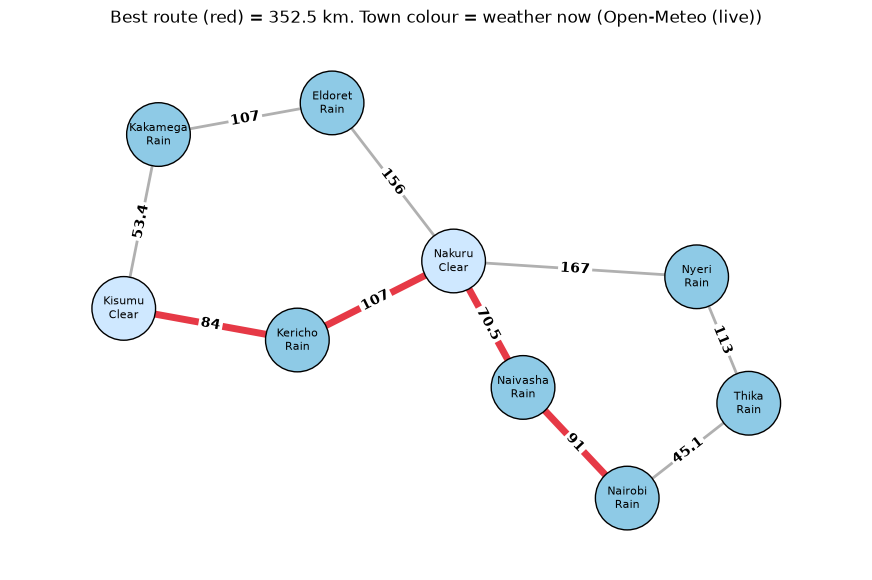

In [10]:
import matplotlib.pyplot as plt
import networkx as nx

pos = {
    "Nairobi": (36.9, -1.5), "Thika": (37.6, -0.9), "Nyeri": (37.3, -0.1),
    "Naivasha": (36.3, -0.8), "Nakuru": (35.9, 0.0), "Kericho": (35.0, -0.5),
    "Kisumu": (34.0, -0.3), "Kakamega": (34.2, 0.8), "Eldoret": (35.2, 1.0),
}
G = nx.Graph()
for a, b, km in roads:
    G.add_edge(a, b, km=km)

weather_colour = {"Clear": "#cfe8ff", "Cloudy": "#d9d9d9", "Rain": "#8ecae6", "Fog": "#e9c46a", "Storm": "#e76f51"}

fig, ax = plt.subplots(figsize=(11, 7))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#b0b0b0", width=2)
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=list(zip(path, path[1:])), edge_color="#e63946", width=5)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=2100, edgecolors="black",
                       node_color=[weather_colour.get(weather_now.get(n), "#cfe8ff") for n in G.nodes])
nx.draw_networkx_labels(G, pos, ax=ax, font_size=8,
                        labels={n: f"{n}\n{weather_now.get(n, '')}" for n in G.nodes})
nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels={(a, b): f"{km:g}" for a, b, km in roads},
                             font_size=10, font_weight="bold",
                             bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
ax.set_title(f"Best route (red) = {cost} km. Town colour = weather now ({weather_source})", fontsize=12)
ax.margins(0.12); ax.axis("off")
plt.show()

The same search drawn as a tree in Exercise 3 (number beside each town = order it was expanded):

![Uniform-cost search tree](uniform-cost-search-tree.png)

**Query 2: How should the trailer drive each leg of the route?** For every road on the best route, the KB looks up the weather at the town the trailer is heading to and gives the action and speed.

In [11]:
legs = []
for a, b in zip(path, path[1:]):
    w = weather_now.get(b, "Clear")
    rule = weather_rules.get(w, UNKNOWN)
    hours = Road(a, b) / rule["speed"] if rule["speed"] else None
    legs.append({"Leg": f"{a} -> {b}", "km": Road(a, b), "Weather at arrival": w,
                 "Action": rule["action"], "Speed (km/h)": rule["speed"],
                 "Time at that speed (h)": round(hours, 1) if hours else "wait"})
display(pd.DataFrame(legs).style.hide(axis="index").format({"km": "{:.1f}"})
        .set_properties(**{"text-align": "left"}))

Leg,km,Weather at arrival,Action,Speed (km/h),Time at that speed (h)
Nairobi -> Naivasha,91.0,Rain,"Slow down, double the following distance.",50,1.800000
Naivasha -> Nakuru,70.5,Clear,Normal driving.,80,0.900000
Nakuru -> Kericho,107.0,Rain,"Slow down, double the following distance.",50,2.100000
Kericho -> Kisumu,84.0,Clear,Normal driving.,80,1.100000


**Query 3: Single questions to the KB**, like the template's `traffic_advice` examples, including one input the KB does not know (Purple).

In [12]:
for question in [{"signal": "Flashing Yellow"}, {"signal": "Red"}, {"sign": "Weighbridge"},
                 {"signal": "Green", "weather": "Fog"}, {"signal": "Purple"}]:
    a = trailer_advice(**question)
    print(f"{str(question):40s} -> {a['decision']}  | {'; '.join(a['reasons'])}")

{'signal': 'Flashing Yellow'}            -> Drive at most 20 km/h.  | signal = Flashing Yellow: Slow down, look both ways, then go.
{'signal': 'Red'}                        -> Stop / do not move.  | signal = Red: Stop. It is unsafe to move.
{'sign': 'Weighbridge'}                  -> Drive at most 10 km/h.  | sign = Weighbridge: Trailer must pull in and be weighed.
{'signal': 'Green', 'weather': 'Fog'}    -> Drive at most 30 km/h.  | signal = Green: Go. It is safe to proceed.; weather = Fog: Headlights on, slow down a lot.
{'signal': 'Purple'}                     -> Stop / do not move.  | signal = Purple: Unknown input. Proceed with caution or stop.


## Step 9: Debugging the Knowledge Base [2 marks]
We test the agent with normal, new and **faulty** inputs to see how it reacts. Inputs it does not know should get the safe fallback answer, never a crash.

In [13]:
test_cases = ["Red", "Yellow", "Green", "Blue", "Teal", "None", "Purple"]
for colour in test_cases:
    print(f"{colour:8s} -> {trailer_advice(signal=colour)['decision']:30s} {Action('signal', colour)}")

print("\nUnknown town:", best_route("Nairobi", "Mombasa"))
print("Unknown sign:", Action("sign", "Low Flying Planes"))

Red      -> Stop / do not move.            Stop. It is unsafe to move.
Yellow   -> Drive at most 20 km/h.         Slow down and prepare to stop.
Green    -> Drive at most 80 km/h.         Go. It is safe to proceed.
Blue     -> Stop / do not move.            Unknown input. Proceed with caution or stop.
Teal     -> Stop / do not move.            Unknown input. Proceed with caution or stop.
None     -> Stop / do not move.            Unknown input. Proceed with caution or stop.
Purple   -> Stop / do not move.            Unknown input. Proceed with caution or stop.

Unknown town: (None, None)
Unknown sign: Unknown input. Proceed with caution or stop.


**Fixing what the tests showed.** "None" means the traffic light is off (for example, a power cut). The agent treated it as unknown and stopped. We decided the trailer should treat a dead light like a give-way junction, so we add that fact and test again. We also test a **closed road**: if Nakuru to Kericho is closed, the agent should find the next best route.

In [14]:
add_new_fact("signal", "None", "Light is off. Treat it as Give Way: slow down, check, then go.", speed=20, can_go=True)
print("None  ->", trailer_advice(signal="None")["decision"], "|", Action("signal", "None"))

# Closed road test: remove Nakuru - Kericho, ask again, then put it back
km = graph["Nakuru"].pop("Kericho"); graph["Kericho"].pop("Nakuru")
print("\nNakuru-Kericho closed. BestRoute:", best_route("Nairobi", "Kisumu"))
graph["Nakuru"]["Kericho"] = graph["Kericho"]["Nakuru"] = km
print("Road reopened.        BestRoute:", best_route("Nairobi", "Kisumu"))

# Final check: the KB still gives the Exercise 3 answer
assert best_route("Nairobi", "Kisumu") == (["Nairobi", "Naivasha", "Nakuru", "Kericho", "Kisumu"], 352.5)
print("\nCheck passed: best route is still 352.5 km, same as Exercise 3.")

New signal fact added: None -> Light is off. Treat it as Give Way: slow down, check, then go. (speed 20, can go: True)
None  -> Drive at most 20 km/h. | Light is off. Treat it as Give Way: slow down, check, then go.

Nakuru-Kericho closed. BestRoute: (['Nairobi', 'Naivasha', 'Nakuru', 'Eldoret', 'Kakamega', 'Kisumu'], 477.9)
Road reopened.        BestRoute: (['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu'], 352.5)

Check passed: best route is still 352.5 km, same as Exercise 3.


## Step 10: Final reflection (challenges or recommended improvements) [3 marks]
**What worked**
* Keeping all knowledge in dictionaries meant we could add new signals, signs, weather types and even roads **without changing any code**, and the route search used the new road immediately.
* Combining rules with "most cautious wins" gave sensible answers when two rules disagree (for example Green light in Fog gives 30 km/h, not 80).
* The KB gives the same best route as Exercise 3 (Nairobi, Naivasha, Nakuru, Kericho, Kisumu, 352.5 km), so the old search knowledge carried over correctly.

**Challenges**
* **Data freshness.** Road distances were measured once on Google Maps (16 Oct 2026) and Google rounds to whole km above 100 km. Weather changes every hour, so the answer to "how should we drive" can change between runs.
* **Unknown inputs.** At first the agent stopped for a dead traffic light ("None"). Testing showed this, and we fixed it by adding a new fact.
* **Interaction in an automatic run.** `input()` fails when nobody can type, so we wrapped it in `ask()` with default answers.

**Limits and recommended improvements**
* The cost is distance only. Travel time, traffic, tolls and road quality are not in the KB. A traffic API (for example Google Distance Matrix) could add travel time.
* The speed values in our rules are group assumptions. A next version should load the official Kenyan speed limits for heavy vehicles from NTSA.
* Weather is checked for the town, not along the road between towns.
* A proper rule engine with first-order logic and forward chaining would let rules depend on each other (e.g. *Rain and Night means Fog lights*), which simple dictionary lookups cannot do.

## Group-work evidence

### Team photo
![Group involvement photo](group-involvement-4.jpeg)

### GitHub links
Alvin's repository is the original. Jeremy and Travis each forked it.

| Group member | Repository | GitHub link |
|---|---|---|
| Muriuki Alvin Murithi | Original | [cypher-30/Knowledge-Engineering](https://github.com/cypher-30/Knowledge-Engineering) |
| Sebudde Jeremy Mwesigwa | Fork | [byterem/Knowledge-Engineering](https://github.com/byterem/Knowledge-Engineering) |
| Mutungi Travis Njenga | Fork | [Trav1s5/Knowledge-Engineering](https://github.com/Trav1s5/Knowledge-Engineering) |

The forks page of the original repository lists both forks:

![Forks page of cypher-30/Knowledge-Engineering](forks-4.png)